# Stage 1 Data Analysis Athena

### Imports

In [2]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mcap.reader import make_reader
from mcap_ros2.decoder import DecoderFactory

### Check on Topics

#### Real Data

In [3]:
root = "data-real-athena/data-rear-axle-servo"
path = next(os.path.join(d, f) for d, _, fs in sorted(os.walk(root)) for f in sorted(fs) if f.endswith(".mcap"))
print(path)
with open(path, "rb") as f:
    reader = make_reader(f)
    summary = reader.get_summary()
    for ch_id, ch in summary.channels.items():
        schema = summary.schemas[ch.schema_id]
        count = summary.statistics.channel_message_counts.get(ch_id, 0)
        print(f"{ch.topic:40s} {schema.name:40s} {count}")

data-real-athena/data-rear-axle-servo/stage-1-test-circle-left-rear-axle/stage-1-test-circle-left-rear-axle.mcap
/rosout                                  rcl_interfaces/msg/Log                   57
/events/write_split                      rosbag2_interfaces/msg/WriteSplitEvent   0
/parameter_events                        rcl_interfaces/msg/ParameterEvent        0
/tf                                      tf2_msgs/msg/TFMessage                   5877
/tf_static                               tf2_msgs/msg/TFMessage                   1
/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker geometry_msgs/msg/PoseStamped            5877
/commands/motor/speed                    std_msgs/msg/Float64                     619
/commands/servo/position                 std_msgs/msg/Float64                     732
/sensors/imu/raw                         sensor_msgs/msg/Imu                      1829
/sensors/servo_position_command          std_msgs/msg/Float64                     732
/clicked_poin

### Path Vicon Tracking

The back axle was used

In [4]:
groups = ["0.73", "0.27"]
titles = {
    "0.73": "servo 0.73",
    "0.27": "servo 0.27",
}
max_speed = 5.0
COLS = ["t", "t_log", "px", "py", "pz", "qx", "qy", "qz", "qw"]

VICON_TOPICS = [
    "/vicon/athena/athena",
    "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker",
]
YAW_OFFSET = {
    "/vicon/athena/athena": 0.0,
    "/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker": np.pi / 2,
}
SERVO_TOPICS = ["/commands/servo/position", "/sensors/servo_position_command"]
SERVO_TOL = 0.01
SIDE = {"left": "0.73", "right": "0.27"}
POSE_SCHEMAS = [
    "geometry_msgs/msg/PoseStamped",
    "nav_msgs/msg/Odometry",
    "geometry_msgs/msg/PoseWithCovarianceStamped",
    "geometry_msgs/msg/TransformStamped",
]
IGNORE_TOPICS = ("goal", "cmd", "target", "initial")


def find_base(name="stage-1-testing"):
    d = os.path.abspath(os.getcwd())
    while True:
        if os.path.basename(d) == name:
            return d
        for cand in (os.path.join(d, name), os.path.join(d, "sim-to-real-gap", name)):
            if os.path.isdir(cand):
                return cand
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError(f"'{name}' not found above {os.getcwd()}")
        d = parent


BASE = find_base()
SOURCES = {
    "real": dict(root=os.path.join(BASE, "data-real-athena", "data-rear-axle-servo"),
                 topics=VICON_TOPICS,
                 yaw_offset=YAW_OFFSET,
                 drop_origin=True),
}
for src, cfg in SOURCES.items():
    print(f"{src:5s} {cfg['root']}  exists={os.path.isdir(cfg['root'])}")


def list_channels(path):
    with open(path, "rb") as f:
        summary = make_reader(f).get_summary()
    if summary is None:
        return {}
    counts = summary.statistics.channel_message_counts if summary.statistics else {}
    return {
        ch.topic: (summary.schemas[ch.schema_id].name, counts.get(ch_id))
        for ch_id, ch in summary.channels.items()
    }


def pick_topic(path, candidates):
    channels = list_channels(path)
    for t in candidates:
        if t in channels and channels[t][1] != 0:
            return t
    for schema_name in POSE_SCHEMAS:
        for t, (schema, count) in sorted(channels.items()):
            if schema == schema_name and count != 0 and not any(s in t.lower() for s in IGNORE_TOPICS):
                return t
    print(f"  no pose topic in {os.path.basename(path)}:")
    for t, (schema, count) in sorted(channels.items()):
        print(f"    {t:50s} {schema:45s} {count}")
    return None


def servo_group(path):
    channels = list_channels(path)
    for topic in SERVO_TOPICS:
        if topic in channels and channels[topic][1] != 0:
            with open(path, "rb") as f:
                reader = make_reader(f, decoder_factories=[DecoderFactory()])
                vals = np.array([round(msg.data, 2) for _, _, _, msg in reader.iter_decoded_messages(topics=[topic])])
            steer = vals[np.abs(vals - 0.5) > SERVO_TOL]
            if steer.size:
                v, n = np.unique(steer, return_counts=True)
                return next((g for g in groups if abs(float(g) - v[np.argmax(n)]) <= SERVO_TOL), None)
    name = os.path.basename(path)
    for side, g in SIDE.items():
        if f"-{side}-" in name:
            return g
    return next((g for g in groups if re.search(rf"0[._,-]?{g[2:]}(?!\d)", name)), None)


def extract_pose(msg):
    if hasattr(msg, "pose"):
        pose = msg.pose.pose if hasattr(msg.pose, "pose") else msg.pose
        return pose.position, pose.orientation
    if hasattr(msg, "transform"):
        return msg.transform.translation, msg.transform.rotation
    raise TypeError(f"unknown message type: {type(msg)}")


def load_poses(path, topic):
    rows = []
    with open(path, "rb") as f:
        reader = make_reader(f, decoder_factories=[DecoderFactory()])
        for _, _, message, msg in reader.iter_decoded_messages(topics=[topic]):
            p, q = extract_pose(msg)
            rows.append({
                "t": msg.header.stamp.sec + msg.header.stamp.nanosec * 1e-9,
                "t_log": message.log_time / 1e9,
                "px": p.x, "py": p.y, "pz": p.z,
                "qx": q.x, "qy": q.y, "qz": q.z, "qw": q.w,
            })
    if not rows:
        return pd.DataFrame(columns=COLS)
    df = pd.DataFrame(rows)
    if df["t"].nunique() < 0.5 * len(df):
        print(f"  header stamps unusable in {os.path.basename(path)}, using log time")
        df["t"] = df["t_log"]
    return df.sort_values("t").reset_index(drop=True)


def remove_jumps(df, max_speed=5.0, tol=0.01, origin_eps=1e-3, drop_origin=True):
    if df.empty:
        return df
    if drop_origin:
        at_origin = (df[["px", "py", "pz"]].abs() < origin_eps).all(axis=1)
        df = df[~at_origin].reset_index(drop=True)
        if df.empty:
            return df
    t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()
    keep = np.zeros(len(df), dtype=bool)
    keep[0] = True
    last = 0
    for i in range(1, len(df)):
        if np.hypot(x[i] - x[last], y[i] - y[last]) <= max_speed * (t[i] - t[last]) + tol:
            keep[i] = True
            last = i
    return df[keep].reset_index(drop=True)


def cut_at_gap(df, max_gap=0.2):
    if df.empty:
        return df
    gaps = np.where(df["t"].diff().to_numpy() > max_gap)[0]
    if len(gaps):
        df = df.iloc[:gaps[0]]
    return df.reset_index(drop=True)


def add_velocity(df, win=0.1):
    df = df.copy()
    t, x, y = df["t"].to_numpy(), df["px"].to_numpy(), df["py"].to_numpy()
    if len(t) < 3:
        df["vx"] = df["vy"] = np.nan
        return df
    k = max(1, int(round(win / 2 / np.median(np.diff(t)))))
    i = np.arange(len(t))
    lo, hi = np.clip(i - k, 0, len(t) - 1), np.clip(i + k, 0, len(t) - 1)
    dt = np.where(t[hi] > t[lo], t[hi] - t[lo], np.nan)
    df["vx"] = (x[hi] - x[lo]) / dt
    df["vy"] = (y[hi] - y[lo]) / dt
    return df


def quat_to_yaw(df):
    qw, qx, qy, qz = (df[k].to_numpy() for k in ["qw", "qx", "qy", "qz"])
    return np.arctan2(2 * (qw * qz + qx * qy), 1 - 2 * (qy**2 + qz**2))


def align_start_src(df, topic, yaw_offset, n0=20):
    yaw = quat_to_yaw(df) + yaw_offset.get(topic, 0.0)
    yaw0 = np.arctan2(np.sin(yaw[:n0]).mean(), np.cos(yaw[:n0]).mean())
    dx = df["px"].to_numpy() - df["px"].iloc[0]
    dy = df["py"].to_numpy() - df["py"].iloc[0]
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    out = df.copy()
    out["ax"], out["ay"] = c * dx - s * dy, s * dx + c * dy
    return out


def load_source(src):
    cfg = SOURCES[src]
    dfs = {g: {} for g in groups}
    topic_of = {}
    for subdir, _, files in os.walk(cfg["root"]):
        for file in files:
            if not file.endswith(".mcap"):
                continue
            name = os.path.splitext(file)[0]
            path = os.path.join(subdir, file)
            group = servo_group(path)
            if group is None:
                print(f"[{src}] skipped: {name}")
                continue
            m = re.search(r"-(\d+)(?:-([a-z][a-z_-]*))?$", name)
            run, tag = m.groups() if m else (name, None)
            if tag:
                run = f"{run} ({tag})"

            topic = pick_topic(path, cfg["topics"])
            if topic is None:
                continue

            df = load_poses(path, topic)
            n_before = len(df)
            df = remove_jumps(df, max_speed=max_speed, drop_origin=cfg["drop_origin"])
            df = cut_at_gap(df, max_gap=0.2)
            df = add_velocity(df)
            print(f"[{src}] {name}: servo {group}, {len(df)} msgs ({n_before - len(df)} removed) [{topic}]")

            if not df.empty:
                dfs[group][run] = df
                topic_of[(group, run)] = topic
    return dfs, topic_of


data, topics = {}, {}
for src in SOURCES:
    data[src], topics[src] = load_source(src)

print()
for src in SOURCES:
    for g in groups:
        print(f"{src:5s} {g:9s} {sorted(data[src][g])}")
if not any(data[src][g] for src in SOURCES for g in groups):
    raise RuntimeError("no runs loaded, check paths and topics above")

real  /home/tommy/Documents/autonomous-systems/athena/athena-data-analysis/sim-to-real-gap/stage-1-testing/data-real-athena/data-rear-axle-servo  exists=True
[real] stage-1-test-right-3-rear-axle: servo 0.27, 1209 msgs (559 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-left-3-rear-axle: servo 0.73, 1188 msgs (368 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-right-1-rear-axle: servo 0.27, 1387 msgs (475 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-left-2-rear-axle: servo 0.73, 1861 msgs (367 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-circle-left-rear-axle: servo 0.73, 5877 msgs (0 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-circle-right-rear-axle: servo 0.27, 7327 msgs (0 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
[real] stage-1-test-lef

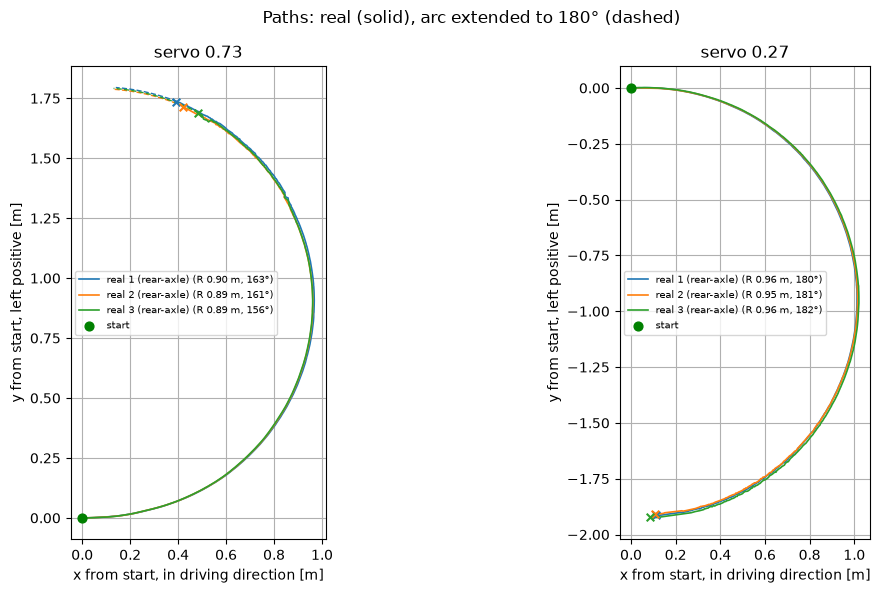

servo           run  R [m]  D [m]  x_max [m]  y_max [m]  winkel gemessen [°]  weg [m]
 0.73 1 (rear-axle)  0.896  1.792      0.968      1.795              163.328    2.836
 0.73 2 (rear-axle)  0.893  1.785      0.962      1.787              161.045    2.818
 0.73 3 (rear-axle)  0.895  1.789      0.961      1.791              156.319    2.842
 0.27 1 (rear-axle)  0.959  1.918      1.012      1.916              179.866    3.038
 0.27 2 (rear-axle)  0.955  1.910      1.015      1.908              180.932    3.026
 0.27 3 (rear-axle)  0.963  1.925      1.021      1.923              181.917    3.056

       R [m]         D [m]        x_max [m]        y_max [m]        winkel gemessen [°]        weg [m]       
        mean    std   mean    std      mean    std      mean    std                mean    std    mean    std
servo                                                                                                        
0.73   0.894  0.002  1.789  0.004     0.964  0.004     1.791  0.004

In [9]:
v_min = 0.5
arc_end = np.pi
colors = plt.cm.tab10.colors


def departure_index(df, v_min):
    v = np.hypot(df["vx"], df["vy"]).to_numpy()
    idx = np.flatnonzero(v > v_min)
    return int(idx[0]) if idx.size else None


def align_at_departure(df, topic, yaw_offset, v_min=0.5, t_yaw=0.1):
    i0 = departure_index(df, v_min)
    if i0 is None:
        return None
    i0 = max(i0 - 1, 0)
    df = df.iloc[i0:].reset_index(drop=True)
    t = df["t"].to_numpy() - df["t"].iloc[0]
    yaw = quat_to_yaw(df) + yaw_offset.get(topic, 0.0)
    w = t <= t_yaw
    yaw0 = np.arctan2(np.sin(yaw[w]).mean(), np.cos(yaw[w]).mean())
    dx = df["px"].to_numpy() - df["px"].iloc[0]
    dy = df["py"].to_numpy() - df["py"].iloc[0]
    c, s = np.cos(-yaw0), np.sin(-yaw0)
    out = df.copy()
    out["tt"] = t
    out["ax"], out["ay"] = c * dx - s * dy, s * dx + c * dy
    return out



def fit_circle(x, y):
    A = np.column_stack([x, y, np.ones_like(x)])
    c, *_ = np.linalg.lstsq(A, x**2 + y**2, rcond=None)
    xc, yc = c[0] / 2, c[1] / 2
    return xc, yc, np.sqrt(c[2] + xc**2 + yc**2)


def extend_arc(a, arc_end, n=200):
    x, y = a["ax"].to_numpy(), a["ay"].to_numpy()
    xc, yc, r = fit_circle(x, y)
    sign = np.sign(yc)
    phi = np.unwrap(np.arctan2(y - yc, x - xc))
    prog = sign * (phi - phi[0])
    m = prog <= arc_end
    ext = phi[m][-1] + sign * np.linspace(0, max(arc_end - prog[m][-1], 0), n)
    sx = np.concatenate([x[m], xc + r * np.cos(ext)])
    sy = np.concatenate([y[m], yc + r * np.sin(ext)])
    return sx, sy, len(x[m]), r, prog[-1]


aligned = {src: {g: {} for g in groups} for src in SOURCES}
for src in SOURCES:
    for g in groups:
        for run, df in data[src][g].items():
            if "circle" in run:
                continue
            a = align_at_departure(df, topics[src][(g, run)], SOURCES[src]["yaw_offset"], v_min)
            if a is None:
                print(f"[{src}] {g} {run}: never faster than {v_min} m/s, skipped")
                continue
            aligned[src][g][run] = a


rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, g in zip(axes, groups):
    runs = sorted(aligned["real"][g])
    for i, run in enumerate(runs):
        c = colors[i % len(colors)]
        a = aligned["real"][g][run]
        sx, sy, k, r, done = extend_arc(a, arc_end)
        ax.plot(a["ax"], a["ay"], "-", color=c, lw=1.2, label=f"real {run} (R {r:.2f} m, {np.degrees(done):.0f}°)")
        ax.plot(sx[k - 1:], sy[k - 1:], "--", color=c, lw=1)
        rows.append({
            "servo": g, "run": run,
            "R [m]": r, "D [m]": 2 * r,
            "x_max [m]": sx.max(), "y_max [m]": np.abs(sy).max(),
            "winkel gemessen [°]": np.degrees(done),
            "weg [m]": np.hypot(np.diff(sx), np.diff(sy)).sum(),
        })
        ax.scatter(a["ax"].iloc[-1], a["ay"].iloc[-1], color=c, marker="x", s=30, zorder=3)
    ax.scatter(0, 0, color="green", s=40, zorder=4, label="start")
    ax.set_title(titles[g])
    ax.set_xlabel("x from start, in driving direction [m]")
    ax.set_ylabel("y from start, left positive [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=7)
fig.suptitle("Paths: real (solid), arc extended to {:.0f}° (dashed)".format(np.degrees(arc_end)))
plt.tight_layout()
plt.show()

masse = pd.DataFrame(rows)
print(masse.round(3).to_string(index=False))
print()
print(masse.drop(columns="run").groupby("servo", sort=False).agg(["mean", "std"]).round(3).to_string())

#### Circle 

The back axle was used

stage-1-test-circle-left-rear-axle: servo 0.73, 5877 msgs (0 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]
stage-1-test-circle-right-rear-axle: servo 0.27, 7327 msgs (0 removed) [/vicon/athena_with_wheel_tracker/athena_with_wheel_tracker]


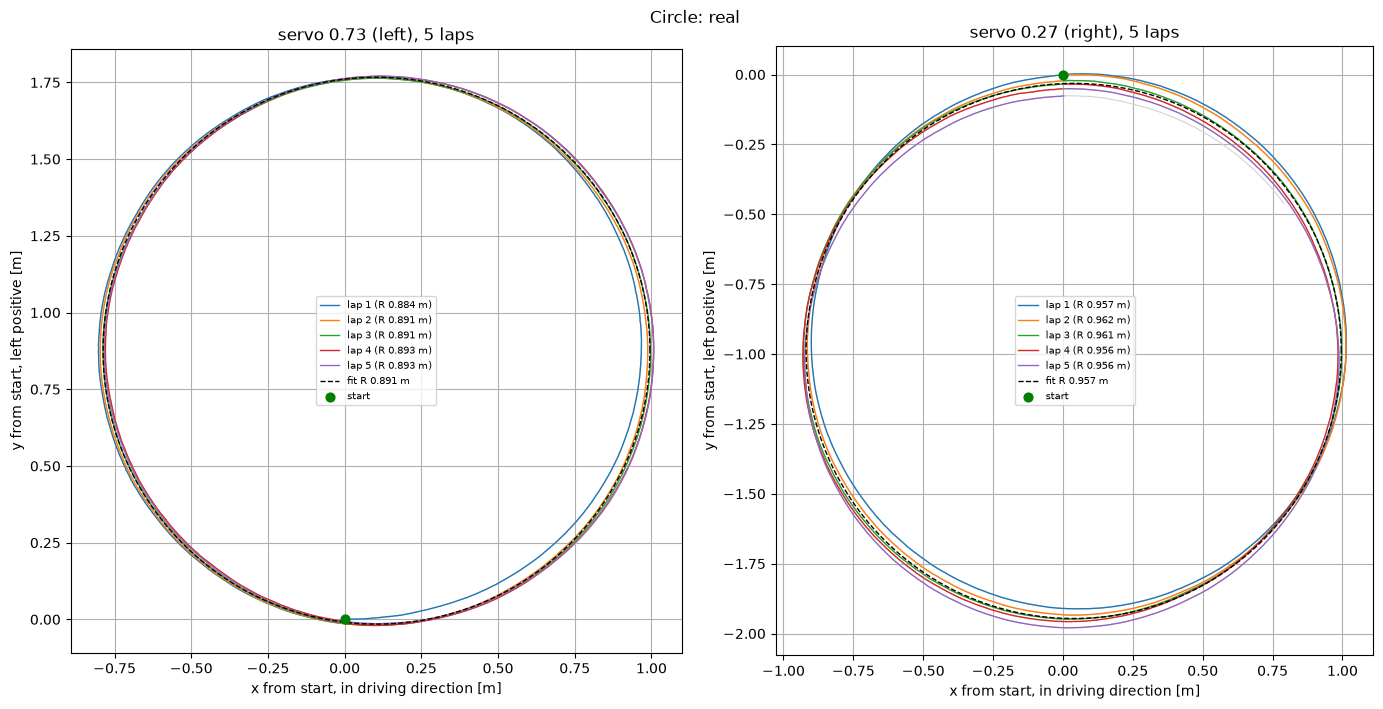

servo  lap  R [m]  D [m]  zeit [s]  v [m/s]
 0.73    1  0.884  1.768     5.563    0.997
 0.73    2  0.891  1.782     5.899    0.949
 0.73    3  0.891  1.782     5.904    0.948
 0.73    4  0.893  1.785     5.910    0.948
 0.73    5  0.893  1.787     5.916    0.948
 0.27    1  0.957  1.914     6.058    0.991
 0.27    2  0.962  1.924     6.207    0.973
 0.27    3  0.961  1.922     6.204    0.973
 0.27    4  0.956  1.913     6.172    0.973
 0.27    5  0.956  1.912     6.172    0.973

       R [m]         D [m]        zeit [s]        v [m/s]       
        mean    std   mean    std     mean    std    mean    std
servo                                                           
0.73   0.890  0.004  1.781  0.008    5.838  0.154   0.958  0.022
0.27   0.958  0.003  1.917  0.006    6.163  0.061   0.977  0.008

          links (0.73)  rechts (0.27)  rechts - links  fehler [%]
R [m]            0.890          0.958           0.068       7.368
D [m]            1.781          1.917           0.136    

In [8]:
circle_files = sorted(
    os.path.join(d, f)
    for d, _, fs in os.walk(os.path.join(BASE, "data-real-athena"))
    for f in fs if f.endswith(".mcap") and "circle" in f
)

circles = {}
for path in circle_files:
    name = os.path.splitext(os.path.basename(path))[0]
    side = next((s for s in SIDE if f"-{s}-" in name), None)
    if side is None:
        print(f"skipped: {name}")
        continue
    topic = pick_topic(path, VICON_TOPICS)
    df = load_poses(path, topic)
    n_before = len(df)
    df = add_velocity(remove_jumps(df, max_speed=max_speed))
    a = align_at_departure(df, topic, YAW_OFFSET, v_min)
    v = np.hypot(a["vx"], a["vy"]).to_numpy()
    a = a.iloc[:np.flatnonzero(v > v_min)[-1] + 1].reset_index(drop=True)
    print(f"{name}: servo {SIDE[side]}, {len(df)} msgs ({n_before - len(df)} removed) [{topic}]")
    circles[name] = (side, a)


rows = []
th = np.linspace(0, 2 * np.pi, 400)
fig, axes = plt.subplots(1, len(circles), figsize=(7 * len(circles), 7), squeeze=False)
for ax, (name, (side, a)) in zip(axes[0], circles.items()):
    x, y, t = a["ax"].to_numpy(), a["ay"].to_numpy(), a["tt"].to_numpy()
    v = np.hypot(a["vx"], a["vy"]).to_numpy()
    xc, yc, r = fit_circle(x, y)
    phi = np.unwrap(np.arctan2(y - yc, x - xc))
    prog = np.maximum.accumulate(np.sign(yc) * (phi - phi[0]))
    n_laps = int(prog[-1] // (2 * np.pi))
    ax.plot(x, y, color="lightgray", lw=0.8)
    for k in range(n_laps):
        m = (prog >= 2 * np.pi * k) & (prog < 2 * np.pi * (k + 1))
        t0, t1 = np.interp([2 * np.pi * k, 2 * np.pi * (k + 1)], prog, t)
        _, _, rk = fit_circle(x[m], y[m])
        ax.plot(x[m], y[m], color=colors[k % len(colors)], lw=1, label=f"lap {k + 1} (R {rk:.3f} m)")
        rows.append({
            "servo": SIDE[side], "lap": k + 1,
            "R [m]": rk, "D [m]": 2 * rk,
            "zeit [s]": t1 - t0, "v [m/s]": v[m].mean(),
        })
    ax.plot(xc + r * np.cos(th), yc + r * np.sin(th), "--", color="k", lw=1, label=f"fit R {r:.3f} m")
    ax.scatter(0, 0, color="green", s=40, zorder=4, label="start")
    ax.set_title(f"servo {SIDE[side]} ({side}), {n_laps} laps")
    ax.set_xlabel("x from start, in driving direction [m]")
    ax.set_ylabel("y from start, left positive [m]")
    ax.set_aspect("equal")
    ax.grid(True)
    ax.legend(fontsize=7)
fig.suptitle("Circle: real")
plt.tight_layout()
plt.show()

laps = pd.DataFrame(rows)
print(laps.round(3).to_string(index=False))
print()
print(laps.drop(columns="lap").groupby("servo", sort=False).agg(["mean", "std"]).round(3).to_string())
print()

mean = laps.drop(columns="lap").groupby("servo", sort=False).mean()
if {SIDE["left"], SIDE["right"]} <= set(mean.index):
    links, rechts = mean.loc[SIDE["left"]], mean.loc[SIDE["right"]]
    fehler = pd.DataFrame({
        f"links ({SIDE['left']})": links,
        f"rechts ({SIDE['right']})": rechts,
        "rechts - links": rechts - links,
        "fehler [%]": (rechts - links) / ((rechts + links) / 2) * 100,
    })
    print(fehler.round(3).to_string())

### Speed Vicon Tracking vs Simulation

For booth the back axle was used

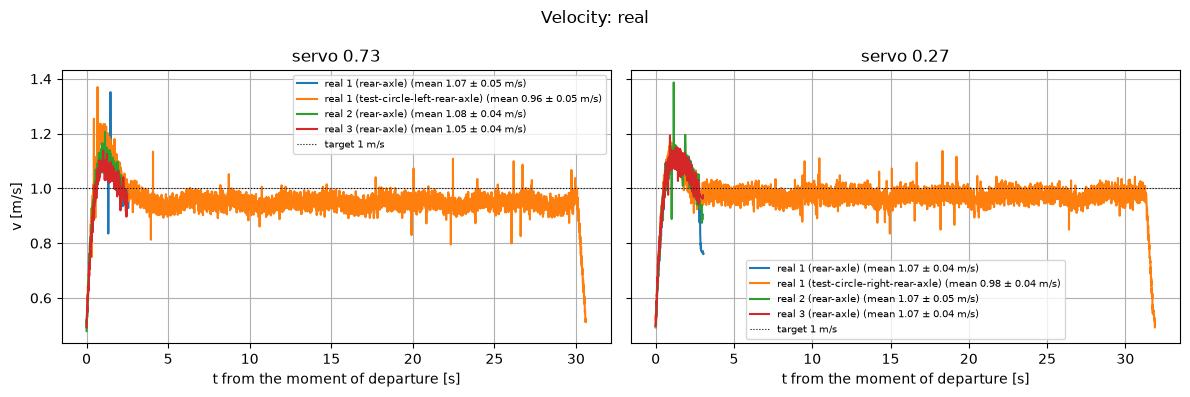

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, g in zip(axes, groups):
    runs = sorted(aligned["real"][g])
    for i, run in enumerate(runs):
        c = colors[i % len(colors)]
        a = aligned["real"][g][run]
        t = a["tt"].to_numpy()
        v = np.hypot(a["vx"], a["vy"]).to_numpy()
        idx = np.flatnonzero(v > v_min)
        if idx.size == 0:
            continue
        t, v = t[:idx[-1] + 1], v[:idx[-1] + 1]
        steady = (t > 0.7) & (t < t[-1] - 0.3)
        label = f"real {run}"
        if steady.any():
            label += f" (mean {v[steady].mean():.2f} ± {v[steady].std():.2f} m/s)"
        ax.plot(t, v, "-", color=c, label=label)
    ax.axhline(1.0, color="k", ls=":", lw=0.8, label="target 1 m/s")
    ax.set_title(titles[g])
    ax.set_xlabel("t from the moment of departure [s]")
    ax.grid(True)
    ax.legend(fontsize=7)
axes[0].set_ylabel("v [m/s]")
fig.suptitle("Velocity: real")
plt.tight_layout()
plt.show()